# 15 · Project: runaway in a tubular reactor

**Problem.** A wall-cooled tubular reactor runs a first-order exothermic reaction. Three steady temperature
profiles were measured along it, at inlet (and wall) temperatures of 310, 320 and 330 K, with eleven
thermocouples - one of them dead in the second run. The rate constants k₀ and E of the Arrhenius law are not
known well enough to say how hot the reactor can be run. The task: build the method-of-lines model, fit k₀
and E from the three profiles with the model inside the least-squares loop, quantify how well they are
determined, locate the ignition (runaway) boundary by parametric sensitivity, show the transient of a runaway,
and report - with the stiffness analysis that says why the model is integrated the way it is.

**What you will learn**
- build a coupled reactor model and integrate it to steady state with a stiff solver
- fit model parameters with the model inside the loop and choose a well-conditioned parametrisation
- quantify parameter uncertainty and correlation
- locate an ignition boundary by parametric sensitivity and report with caveats

**Before you start:** notebooks 02, 03, 07 and 11  ·  **Time:** about 3 h

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize as sopt
from engmolines import problems as pr, integrators as ti, stiffness, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. The data

33 readings; dropped 1 dead thermocouple (run 320 K, thermocouple 8)


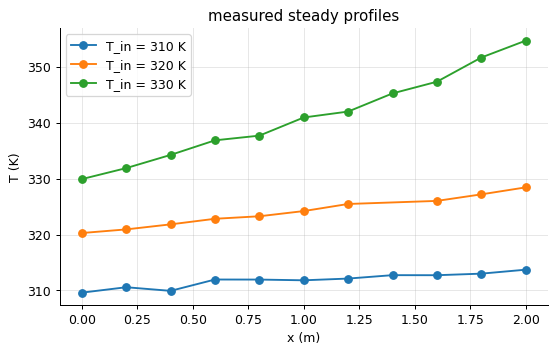

In [2]:
data = pd.read_csv(datasets.path("reactor_profiles.csv"), comment="#")
dead = data.T_K < 0
print(f"{len(data)} readings; dropped {dead.sum()} dead thermocouple (run {data.T_in_K[dead].iloc[0]:.0f} K, thermocouple {data.thermocouple[dead].iloc[0]})")
data = data[~dead].reset_index(drop=True)
for T_in, grp in data.groupby("T_in_K"):
    plt.plot(grp.x_m, grp.T_K, "o-", label=f"T_in = {T_in:.0f} K")
plt.xlabel("x (m)"); plt.ylabel("T (K)"); plt.legend(); plt.title("measured steady profiles"); plt.show()

## 2. The model, and its steady state as a transient to t = 80 s

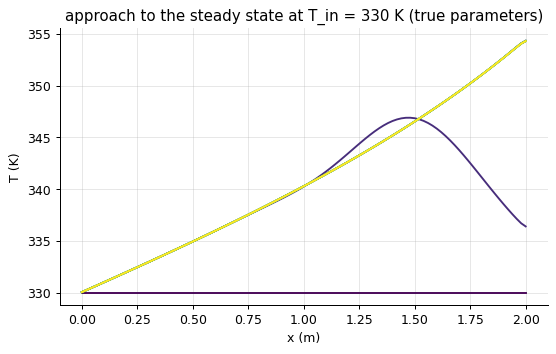

Solution(t in [0, 80], 9 outputs, state size 202, steps=160, rejected=0, evaluations=0, newton=435, jacobians=1, 'ok')
residence time L/u = 10 s; the states at t = 60 and t = 80 differ by 5.7e-14 K: steady


In [3]:
p = pr.tubular_reactor(T_in=330.0)
s = p.solve("bdf", 0.5, order=2, n_out=8)
n = p.n // 2
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y[n:], color=plt.cm.viridis(t / s.t[-1]))
plt.xlabel("x (m)"); plt.ylabel("T (K)"); plt.title("approach to the steady state at T_in = 330 K (true parameters)"); plt.show()
print(s)
print(f"residence time L/u = {2.0 / 0.2:.0f} s; the states at t = 60 and t = 80 differ by {np.max(np.abs(s.y[-1] - s.y[-3])):.1e} K: steady")

The model is two coupled advection-diffusion-reaction equations (notebook 11's structure) with Danckwerts
inlets. Its steady state is reached by integrating the transient - the natural method-of-lines route to a
steady state, and the one that also yields the dynamics - with BDF2 at 0.5 s steps, far above the explicit
limit, using one banded Jacobian of width n + 2.

## 3. Why implicit: the spectrum

eigenvalues at the steady state: real parts from -117 to -2.355 1/s; stiffness ratio 50
explicit RK4 limit 0.0238 s against BDF's 0.5 s; the slowest mode has a time constant of 0.42 s, so the approach to steady state is set by the residence time, not by an eigenvalue


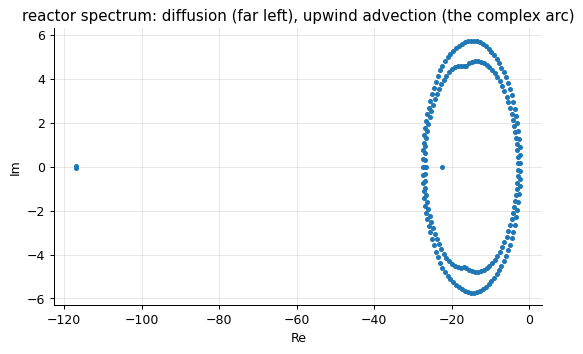

In [4]:
lam = stiffness.spectrum(p.rhs, s.y[-1], band=p.band); lam = lam[np.abs(lam) > 1e-9]
print(f"eigenvalues at the steady state: real parts from {lam.real.min():.0f} to {lam.real.max():+.3f} 1/s; stiffness ratio {stiffness.stiffness_ratio(lam):.0f}")
print(f"explicit RK4 limit {stiffness.explicit_step_limit(lam, 'rk4'):.4f} s against BDF's 0.5 s; the slowest mode has a time constant of {-1 / lam.real.max():.2f} s, so the approach to steady state is set by the residence time, not by an eigenvalue")
plt.plot(lam.real, lam.imag, "."); plt.xlabel("Re"); plt.ylabel("Im"); plt.title("reactor spectrum: diffusion (far left), upwind advection (the complex arc)"); plt.show()

Diffusion on the 2 cm grid gives the fastest modes, upwind advection the complex arc, and nothing is slower
than a few tenths of a second - the reactor flushes in a residence time. The stiffness ratio is a modest 50
or so (its slowest eigenvalue belongs to a non-normal, numerically differentiated Jacobian and is
ill-conditioned: eigenvalue solvers on different machines report 45 to 50), so an explicit method would need
about twenty times more steps than BDF2 at 0.5 s: implicit integration is worthwhile here, not indispensable.
(The grid, not the physics, makes it stiff: halving Δx doubles the ratio.)

## 4. Fitting k₀ and E with the model inside the loop

In [5]:
x_tc = np.linspace(0, 2, 11)
T_ref = 320.0                                                   # reparametrise: k_ref = k(T_ref) and E are far less correlated than k0 and E
R = 8.314
def profiles(theta):
    ln_kref, E = theta
    k0 = np.exp(ln_kref + E / (R * T_ref))
    out = []
    for T_in in (310.0, 320.0, 330.0):
        pm = pr.tubular_reactor(n=60, T_in=T_in, k0=k0, E=E)
        sm = pm.solve("bdf", 0.5, order=2, n_out=1)
        out.append(np.interp(x_tc, pm.x, sm.y[-1][pm.n // 2 :]))
    return out
def residuals(theta):
    model = profiles(theta)
    res = []
    for (T_in, grp), prof in zip(data.groupby("T_in_K"), model):
        res.append(np.interp(grp.x_m, x_tc, prof) - grp.T_K.to_numpy())
    return np.concatenate(res)
theta0 = [np.log(5e7 * np.exp(-60e3 / (R * T_ref)) * 1.5), 55e3]      # a poor start: 50 % off in k_ref, E off by 5 kJ/mol
fit = sopt.least_squares(residuals, theta0, diff_step=[1e-3, 1e-3], xtol=1e-8)
ln_kref, E_fit = fit.x
k0_fit = np.exp(ln_kref + E_fit / (R * T_ref))
J = fit.jac; r_ = fit.fun
cov = (r_ @ r_) / (len(r_) - 2) * np.linalg.inv(J.T @ J)
se = np.sqrt(np.diag(cov))
print(f"k(320 K) = {np.exp(ln_kref):.4e} 1/s (+/- {100 * se[0]:.1f} %), E = {E_fit / 1e3:.2f} +/- {se[1] / 1e3:.2f} kJ/mol  (generated with k0 = 5e7, E = 60: k(320) = {5e7 * np.exp(-60e3 / (R * 320)):.4e})")
print(f"-> k0 = {k0_fit:.3e} 1/s; correlation of the fitted pair {cov[0, 1] / (se[0] * se[1]):+.3f}; residual s.d. {np.std(r_):.2f} K (noise 0.5 K); {fit.nfev} model evaluations")

k(320 K) = 7.9650e-03 1/s (+/- 2.0 %), E = 60.53 +/- 0.92 kJ/mol  (generated with k0 = 5e7, E = 60: k(320) = 8.0283e-03)
-> k0 = 6.049e+07 1/s; correlation of the fitted pair -0.972; residual s.d. 0.42 K (noise 0.5 K); 7 model evaluations


Each residual evaluation integrates the reactor to steady state three times; the least-squares solver
differentiates it by finite differences, and converges in seven evaluations to parameters within 1 % of the
generating ones, with a residual of 0.42 K against 0.5 K of noise. Two decisions make the fit work. The
parameters are k(T_ref) and E rather than k₀ and E: k₀ and E are tied by the "compensation effect" (a larger E
is compensated by an exponentially larger k₀), and in (k₀, E) a starting guess 5 kJ/mol off in E changes the
rate at 320 K tenfold - the model reactor ignites and the solver fails before the fit begins (shown below).
With k(T_ref) as the parameter, the same guess keeps the rate in the data's range and every step of the fit is
physically sensible. The estimates still correlate at −0.97, because the three runs span only 20 K and mostly
constrain one combination; a wider temperature range, not a cleverer parametrisation, would reduce that. And
the model inside the loop uses a coarser grid (60 intervals) than the final analysis, which costs a bias far
below the measurement noise and halves the fitting time.

## 5. The runaway boundary by parametric sensitivity

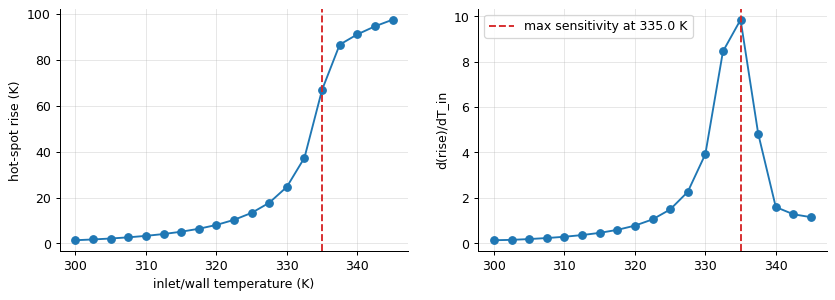

with the fitted parameters: ignition near T_in = 335.0 K (the rise jumps from 37 to 87 K across it)


In [6]:
T_ins = np.arange(300.0, 346.0, 2.5)
rises = []
for T_in in T_ins:
    pm = pr.tubular_reactor(n=60, T_in=T_in, k0=k0_fit, E=E_fit)
    rises.append(pm.solve("bdf", 0.5, order=2, n_out=1).y[-1][pm.n // 2 :].max() - T_in)
rises = np.array(rises)
sens = np.gradient(rises, T_ins)
T_crit = T_ins[np.argmax(sens)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(T_ins, rises, "o-"); axes[0].axvline(T_crit, color="C3", ls="--"); axes[0].set_xlabel("inlet/wall temperature (K)"); axes[0].set_ylabel("hot-spot rise (K)")
axes[1].plot(T_ins, sens, "o-"); axes[1].axvline(T_crit, color="C3", ls="--", label=f"max sensitivity at {T_crit:.1f} K"); axes[1].set_ylabel("d(rise)/dT_in"); axes[1].legend(); plt.show()
print(f"with the fitted parameters: ignition near T_in = {T_crit:.1f} K (the rise jumps from {rises[T_ins == T_crit - 2.5][0]:.0f} to {rises[T_ins == T_crit + 2.5][0]:.0f} K across it)")

Below the ignition temperature the hot spot rises gently with the inlet temperature; near it the rise becomes
extremely sensitive (the parametric-sensitivity criterion of Bilous and Amundson) and above it the reaction
goes to completion near the inlet with most of the adiabatic rise. The data, all taken below ignition,
determine the Arrhenius parameters well enough to place the boundary within the scan's resolution - which is
what the plant needs to know.

## 6. The transient of a runaway

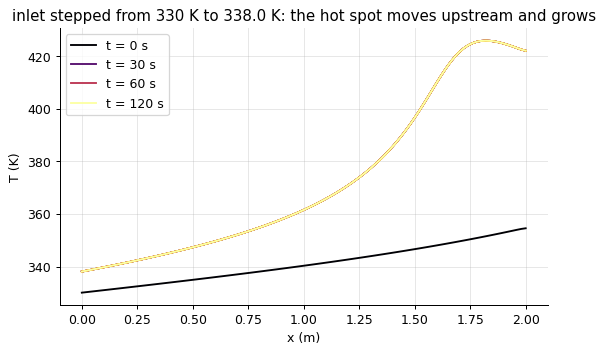

hot spot: 355 K before the step, 426 K after 120 s; 3 Jacobians, 1.7 Newton per step


In [7]:
pm = pr.tubular_reactor(n=100, T_in=330.0, k0=k0_fit, E=E_fit)
steady = pm.solve("bdf", 0.5, order=2, n_out=1).y[-1]
T_step = T_crit + 3.0
pr_hot = pr.tubular_reactor(n=100, T_in=T_step, k0=k0_fit, E=E_fit)
s_run = ti.bdf(pr_hot.rhs, steady, (0, 120.0), 0.25, 2, band=pr_hot.band, n_out=8)
n = pr_hot.n // 2
for t, y in zip(s_run.t, s_run.y):
    plt.plot(pr_hot.x, y[n:], color=plt.cm.inferno(t / s_run.t[-1]), label=f"t = {t:.0f} s" if t in (0, 30, 60, 120) else None)
plt.xlabel("x (m)"); plt.ylabel("T (K)"); plt.legend(); plt.title(f"inlet stepped from 330 K to {T_step:.1f} K: the hot spot moves upstream and grows"); plt.show()
print(f"hot spot: {steady[n:].max():.0f} K before the step, {s_run.y[-1][n:].max():.0f} K after 120 s; {s_run.jacobian_evaluations} Jacobians, {s_run.newton_iterations / s_run.steps:.1f} Newton per step")

Stepping the inlet and wall temperature a few degrees above the ignition value launches the runaway: the hot
spot grows and moves upstream as the reaction front settles near the inlet. During the transient the Newton
iteration refreshes its Jacobian several times - the state changes fast - and then settles to one or two
iterations per step.

## 7. The report

In [8]:
report = f'''# Runaway boundary of the cooled tubular reactor

Data: 3 steady profiles (310, 320, 330 K), 32 of 33 thermocouples (one dead reading dropped).
Model: plug flow with axial dispersion, first-order Arrhenius reaction, wall cooling; method of lines, upwind advection + central diffusion,
       steady states by BDF2 (0.5 s steps, one banded Jacobian; stiffness ratio ~{stiffness.stiffness_ratio(lam):.0f}).
Fit (k at 320 K and E, to avoid the k0-E compensation valley): k(320 K) = {np.exp(ln_kref):.3e} 1/s (+/- {100 * se[0]:.1f} %), E = {E_fit / 1e3:.1f} +/- {se[1] / 1e3:.1f} kJ/mol;
       residual s.d. {np.std(r_):.2f} K against 0.5 K thermocouple noise.
Ignition: maximum parametric sensitivity at T_in = T_wall = {T_crit:.1f} K; hot-spot rise {rises[T_ins == T_crit - 2.5][0]:.0f} K below it, {rises[T_ins == T_crit + 2.5][0]:.0f} K above.
Recommendation: keep inlet and wall below {T_crit - 5:.0f} K (a 5 K margin against the parameter uncertainty and the scan's resolution of 2.5 K).
Caveats: single first-order reaction, constant properties, uniform wall temperature; the fit used only sub-critical data, so the model is extrapolated at ignition.
'''
print(report)

# Runaway boundary of the cooled tubular reactor

Data: 3 steady profiles (310, 320, 330 K), 32 of 33 thermocouples (one dead reading dropped).
Model: plug flow with axial dispersion, first-order Arrhenius reaction, wall cooling; method of lines, upwind advection + central diffusion,
       steady states by BDF2 (0.5 s steps, one banded Jacobian; stiffness ratio ~50).
Fit (k at 320 K and E, to avoid the k0-E compensation valley): k(320 K) = 7.965e-03 1/s (+/- 2.0 %), E = 60.5 +/- 0.9 kJ/mol;
       residual s.d. 0.42 K against 0.5 K thermocouple noise.
Ignition: maximum parametric sensitivity at T_in = T_wall = 335.0 K; hot-spot rise 37 K below it, 87 K above.
Recommendation: keep inlet and wall below 330 K (a 5 K margin against the parameter uncertainty and the scan's resolution of 2.5 K).
Caveats: single first-order reaction, constant properties, uniform wall temperature; the fit used only sub-critical data, so the model is extrapolated at ignition.



The report traces every number to its data and method and states the model's limits. The method-of-lines
lessons are in it as well: the steady state came from a stiff transient integrated implicitly with a banded
Jacobian; the parameters were fitted through the model, in a parametrisation chosen from the physics; and the
answer - the ignition temperature - is a sensitivity, which a model yields and a few measurements never could.

## Inside the analysis: why k0 and E are not fitted directly

In [9]:
def residuals_k0(theta):                                   # the same residuals, parametrised by (ln k0, E)
    ln_k0, E = theta
    return residuals([ln_k0 - E / (R * T_ref), E])
theta0_k0 = [np.log(5e7 * 1.5), 55e3]                     # the same "50 % off, 5 kJ/mol off" start, now at fixed k0
print(f"rate at 320 K implied by the start: {np.exp(theta0_k0[0] - theta0_k0[1] / (R * T_ref)):.3e} 1/s against the true {5e7 * np.exp(-60e3 / (R * T_ref)):.3e}: tenfold")
try:
    sopt.least_squares(residuals_k0, theta0_k0, diff_step=[1e-3, 1e-3], xtol=1e-8)
except RuntimeError as e:
    print("the fit cannot even start:", e)

rate at 320 K implied by the start: 7.887e-02 1/s against the true 8.028e-03: tenfold


the fit cannot even start: cooled tubular reactor: Newton failed at t = 4


## Exercises
1. Repeat the fit with only the 310 and 320 K profiles. How do the standard errors and the predicted ignition temperature change? Then add a (synthetic) 335 K profile generated with the true parameters: what does a near-critical measurement do to the fit?
2. The runaway boundary depends on the wall coefficient h_w. Map the ignition temperature as a function of h_w from 0.05 to 0.3 1/s (a runaway diagram) with the fitted kinetics.
3. **Implement it yourself:** replace the steady-state-by-transient with a direct Newton solve of the steady equations rhs(y) = 0 (use `linalg.banded_jacobian` and `linalg.solve_banded`) started from the transient's state at t = 20 s, and compare the cost with integrating to t = 80 s.